# Fase 0 por dentro: el bigrama paso a paso

Este notebook reconstruye a mano, celda a celda, lo que hace `bigram.py`:

1. Convertir texto en números (tokenización).
2. Formular el objetivo: predecir el siguiente carácter.
3. Resolverlo **contando**.
4. Medir el error con **cross-entropy**.
5. Resolverlo otra vez con **gradiente**, y comprobar que llega al mismo sitio.
6. Generar texto y ver el efecto de la **temperatura**.

Requisitos: haber ejecutado `python phases/0_bigram/prepare.py` y usar el kernel de `.venv`. Todo corre en CPU en unos segundos.

In [1]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

# Works whether the kernel starts in the repo root or in the phase folder.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())

text = (ROOT / "data" / "quijote" / "input.txt").read_text(encoding="utf-8")
print(f"{len(text):,} caracteres\n")
print(text[:300])

2,110,705 caracteres

El ingenioso hidalgo don Quijote de la Mancha



por Miguel de Cervantes Saavedra





El ingenioso hidalgo don Quijote de la Mancha



Tasa


Testimonio de las erratas


El Rey


Al Duque de Béjar


Prólogo


Al libro de don Quijote de la Mancha



Que trata de la condición y ejercicio del famoso
h


## 1. Tokenización: de caracteres a números

Una red neuronal solo opera con números. El tokenizer más simple asigna un id a cada carácter distinto del corpus.

In [2]:
chars = sorted(set(text))
stoi = {c: i for i, c in enumerate(chars)}  # string -> id


def encode(s):
    return [stoi[c] for c in s]


def decode(ids):
    return "".join(chars[i] for i in ids)


V = len(chars)
print("Tamaño del vocabulario:", V)
print(repr("".join(chars)))
ids = encode("En un lugar")
print(ids, "->", repr(decode(ids)))

Tamaño del vocabulario: 92
'\n !"\'(),-.01234567:;?ABCDEFGHIJLMNOPQRSTUVWXYZ]abcdefghijlmnopqrstuvxyz¡«»¿ÁÉÍÑÓÚàáéíïñóùúü—'
[25, 59, 1, 66, 59, 1, 57, 66, 53, 47, 63] -> 'En un lugar'


## 2. El objetivo: predecir el siguiente carácter

Los *targets* son los mismos datos desplazados una posición. De un solo trozo de texto salen muchos ejemplos de entrenamiento: uno por posición.

El split es el mismo 90/10 que usan todas las fases.

In [3]:
data = torch.tensor(encode(text))
split = int(0.9 * len(data))
train, val = data[:split], data[split:]

x, y = train[:12], train[1:13]
for t in range(8):
    print(f"contexto {decode(x[: t + 1].tolist())!r:12} -> objetivo {decode([y[t].item()])!r}")

contexto 'E'          -> objetivo 'l'
contexto 'El'         -> objetivo ' '
contexto 'El '        -> objetivo 'i'
contexto 'El i'       -> objetivo 'n'
contexto 'El in'      -> objetivo 'g'
contexto 'El ing'     -> objetivo 'e'
contexto 'El inge'    -> objetivo 'n'
contexto 'El ingen'   -> objetivo 'i'


Un transformer usa **todo** el contexto de la izquierda. El bigrama solo usa **el último carácter**: para él, los ocho ejemplos de arriba se reducen a pares `(actual, siguiente)`.

## 3. El bigrama por conteo

Si solo vemos el carácter actual, la mejor predicción posible es la frecuencia observada: `P(b | a) = cuántas veces sigue b a a / cuántas veces aparece a`. Se suma 1 a cada celda (*add-one smoothing*) para que ningún par tenga probabilidad 0, igual que en `bigram.py`.

In [4]:
counts = torch.zeros(V, V)
counts.index_put_((train[:-1], train[1:]), torch.ones(len(train) - 1), accumulate=True)
probs = (counts + 1) / (counts + 1).sum(dim=1, keepdim=True)  # each row sums to 1


def top_next(c, k=5):
    top = probs[stoi[c]].topk(k)
    return [(decode([i]), round(p, 3)) for p, i in zip(top.values.tolist(), top.indices.tolist())]


for c in ["q", "ñ", " ", "."]:
    print(f"{c!r:5} -> {top_next(c)}")

'q'   -> [('u', 0.997), (' ', 0.0), ('!', 0.0), ('"', 0.0), ("'", 0.0)]
'ñ'   -> [('o', 0.579), ('a', 0.323), ('e', 0.034), ('í', 0.017), ('i', 0.009)]
' '   -> [('d', 0.107), ('e', 0.088), ('l', 0.085), ('a', 0.075), ('s', 0.072)]
'.'   -> [('\n', 0.487), (' ', 0.473), ('.', 0.017), ('»', 0.006), (',', 0.002)]


Tras `q` casi siempre viene `u`: el modelo ya ha aprendido una regla del español. Toda la "inteligencia" del bigrama cabe en esta tabla `V×V`. Así se ve un trozo:

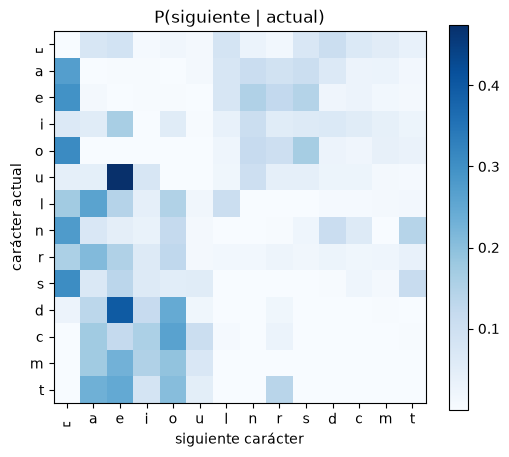

In [5]:
subset = list(" aeioulnrsdcmt")
idx = [stoi[c] for c in subset]
labels = ["␣" if c == " " else c for c in subset]

plt.figure(figsize=(6, 5))
plt.imshow(probs[idx][:, idx], cmap="Blues")
plt.xticks(range(len(subset)), labels)
plt.yticks(range(len(subset)), labels)
plt.xlabel("siguiente carácter")
plt.ylabel("carácter actual")
plt.title("P(siguiente | actual)")
plt.colorbar()
plt.show()

## 4. La loss: cross-entropy a mano

Para cada posición se mira **qué probabilidad dio el modelo al carácter que de verdad vino**, y se toma `-log p`. Si el modelo acierta con seguridad (p≈1), la penalización es ≈0. Si le dio poca probabilidad, la penalización crece mucho.

La loss es la media de esas penalizaciones. El modelo que no sabe nada (uniforme, p = 1/V) obtiene exactamente `ln(V)`.

In [6]:
word = " Mancha"
ids = encode(word)
penalties = []
for a, b in zip(ids, ids[1:]):
    p = probs[a, b].item()
    penalties.append(-math.log(p))
    print(f"P({decode([b])!r} | {decode([a])!r}) = {p:.3f}   -log p = {-math.log(p):.3f}")
print(f"loss media en {word!r}: {sum(penalties) / len(penalties):.3f}")

val_loss = -probs[val[:-1], val[1:]].log().mean().item()
print(f"\nBaseline uniforme ln(V)  = {math.log(V):.4f}")
print(f"Bigrama por conteo (val) = {val_loss:.4f} nats = {val_loss / math.log(2):.3f} bits/char")

P('M' | ' ') = 0.003   -log p = 5.966
P('a' | 'M') = 0.482   -log p = 0.730
P('n' | 'a') = 0.109   -log p = 2.213
P('c' | 'n') = 0.062   -log p = 2.785
P('h' | 'c') = 0.107   -log p = 2.234
P('a' | 'h') = 0.459   -log p = 0.779
loss media en ' Mancha': 2.451

Baseline uniforme ln(V)  = 4.5218
Bigrama por conteo (val) = 2.3047 nats = 3.325 bits/char


**Bits por carácter** = loss / ln 2. Es la misma cantidad en otra unidad: cuántas preguntas de sí/no harían falta, de media, para adivinar el siguiente carácter.

## 5. Lo mismo, aprendido con gradiente

Ahora olvidamos el conteo. La tabla pasa a ser una matriz de **logits** `W` (números libres), y la convertimos en probabilidades con **softmax**: `p = exp(logits) / sum(exp(logits))`.

Primero, la cross-entropy hecha a mano y comparada con la de PyTorch:

In [7]:
W = torch.zeros(V, V, requires_grad=True)  # all zeros = uniform distribution
xb, yb = train[:5], train[1:6]

logits = W[xb]  # (5, V): the row of the current character, nothing more
p = logits.exp() / logits.exp().sum(dim=1, keepdim=True)  # softmax
manual = -p[torch.arange(5), yb].log().mean()

print(f"a mano: {manual.item():.4f} | F.cross_entropy: {F.cross_entropy(logits, yb).item():.4f} | ln(V): {math.log(V):.4f}")

a mano: 4.5218 | F.cross_entropy: 4.5218 | ln(V): 4.5218


**¿Qué dice el gradiente?** Para la cross-entropy, la derivada respecto a los logits es `p - one_hot(objetivo)`: sube el logit del carácter correcto en `1 - p` y baja el de los demás en `p`. Es todo lo que hace backpropagation en este modelo.

In [8]:
logits = torch.zeros(V, requires_grad=True)
F.cross_entropy(logits[None], torch.tensor([stoi["u"]])).backward()
print(f"grad del correcto ('u'): {logits.grad[stoi['u']].item():+.4f}   (= 1/V - 1 = {1 / V - 1:+.4f})")
print(f"grad de otro    ('a'): {logits.grad[stoi['a']].item():+.4f}   (= 1/V     = {1 / V:+.4f})")

grad del correcto ('u'): -0.9891   (= 1/V - 1 = -0.9891)
grad de otro    ('a'): +0.0109   (= 1/V     = +0.0109)


El optimizador **resta** el gradiente: el logit correcto sube y los demás bajan. Repetido sobre millones de pares, la tabla converge a las frecuencias del conteo.

val entrenado: 2.3064 | val por conteo: 2.3047


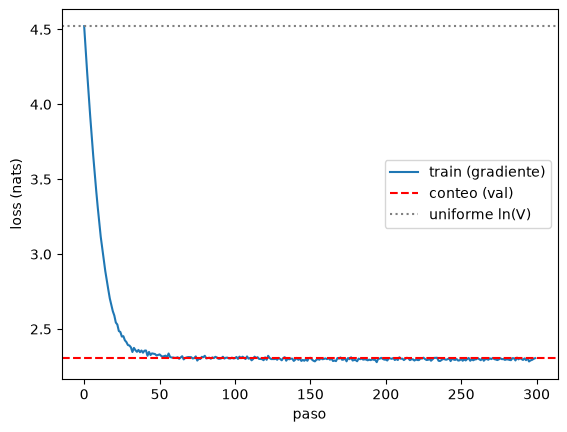

In [9]:
torch.manual_seed(0)
W = torch.zeros(V, V, requires_grad=True)
optimizer = torch.optim.AdamW([W], lr=0.1, weight_decay=0.0)
history = []
for step in range(300):
    i = torch.randint(len(train) - 1, (32768,))
    loss = F.cross_entropy(W[train[i]], train[i + 1])
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    history.append(loss.item())

with torch.no_grad():
    trained_val = F.cross_entropy(W[val[:-1]], val[1:]).item()
print(f"val entrenado: {trained_val:.4f} | val por conteo: {val_loss:.4f}")

plt.plot(history, label="train (gradiente)")
plt.axhline(val_loss, color="red", linestyle="--", label="conteo (val)")
plt.axhline(math.log(V), color="gray", linestyle=":", label="uniforme ln(V)")
plt.xlabel("paso")
plt.ylabel("loss (nats)")
plt.legend()
plt.show()

Los dos métodos llegan al mismo sitio porque minimizan **el mismo objetivo**. Esa coincidencia es la prueba de que el bucle de entrenamiento está bien. A partir de la fase 1 ya no habrá solución por conteo y el gradiente será la única opción.

## 6. Generar texto y la temperatura

Generar es repetir: mirar el último carácter, tomar su fila de probabilidades, muestrear y añadir. La **temperatura** divide los logits antes del softmax. Con T < 1 la distribución se afila (más conservadora) y con T > 1 se aplana (más aleatoria).

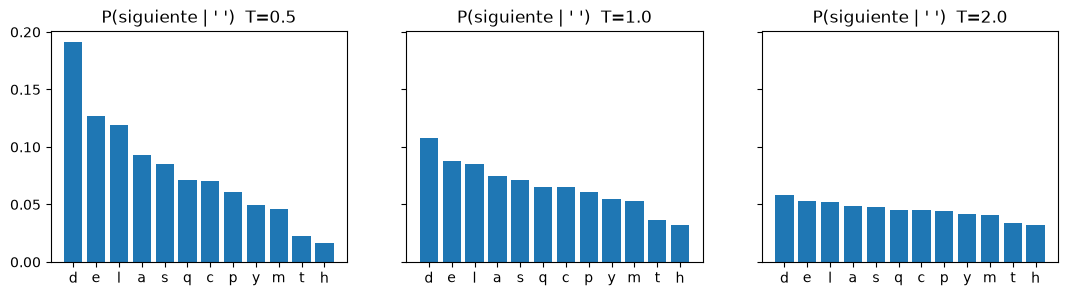

T=0.5: 'En un lugar de la Mancha en n s mpos mindo quen en le anta s po pes a a ca lla ta la n le lare cas la a tosarale hadin e yo fan e e que la s\nde ques estune llos de erere de c'

T=1.0: 'En un lugar de la Mancha en ndin pió mindos\n\n—r en leñantiesu mes queranca Xásita yade lestire cas la a tosar, do limíano o fende e quy\nlle els y que quene llos der y enta qu'

T=2.0: "En un lugar de la Mancha RGAnlilguió mpa,.\n—den NTbl1ú deñVsuí:\npesuazgocÑ7Xásitañocune\n\nZù?reocas,óÁ¡A2F éarZo.\nLlimíÑU2ÉXEIcábe e Pl\n\nBje tásénarcaú«ó Anquá.óvude y,.I''Sic"



In [10]:
log_probs = probs.log()  # the logits of the counting model

fig, axes = plt.subplots(1, 3, figsize=(13, 3), sharey=True)
top = log_probs[stoi[" "]].topk(12).indices
for ax, T in zip(axes, [0.5, 1.0, 2.0]):
    p = F.softmax(log_probs[stoi[" "]] / T, dim=-1)
    ax.bar([decode([i]) for i in top.tolist()], p[top])
    ax.set_title(f"P(siguiente | ' ')  T={T}")
plt.show()


def sample(start, n, temperature):
    g = torch.Generator().manual_seed(42)
    out = encode(start)
    for _ in range(n):
        p = F.softmax(log_probs[out[-1]] / temperature, dim=-1)
        out.append(torch.multinomial(p, 1, generator=g).item())
    return decode(out)


for T in [0.5, 1.0, 2.0]:
    print(f"T={T}: {sample('En un lugar de la Mancha', 150, T)!r}\n")

## Conclusión

El bigrama produce sílabas pronunciables y poco más: con un solo carácter de contexto no puede saber en qué palabra está. Esa es la limitación que resuelve la fase 1, con un modelo que mira **todo** el contexto anterior y aprende qué partes importan: la atención.